# 03 · Когорты и retention

Шаг 4 плана. Когорта — месяц **первой покупки**, возраст считается от **даты** первой покупки блоками по 30 дней (журнал 2026-09-15, Аникин). Ячейка без полного окна наблюдения — NaN, а не 0.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, figures
from data import CLEAN_PARQUET
from features import build_features, cohort_tables, calendar_retention
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
tx = pd.read_parquet(CLEAN_PARQUET)
feats = build_features(tx)
size, ret, rpc = cohort_tables(tx, feats)
size.to_frame().T

first_purchase,2009-12,2010-01,2010-02,2010-03,2010-04,2010-05,2010-06,2010-07,2010-08,2010-09,...,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
size,951,368,375,441,294,255,267,185,163,239,...,179,106,111,108,101,107,188,221,191,28


## Когорта 2009-12 не является когортой привлечения

Окно данных начинается 2009-12-01, поэтому «первая покупка» старых клиентов в декабре 2009 — просто первая покупка в окне. Размер когорты это показывает.

In [2]:
print('медиана размера других когорт:', int(size.iloc[1:].median()), ' · 2009-12:', int(size.iloc[0]))
pd.DataFrame({'ret_age1': ret[1], 'ret_age6': ret[6]}).round(3).iloc[[0,1,2,3,4,5]]

медиана размера других когорт: 186  · 2009-12: 951


,ret_age1,ret_age6
cohort,,
2009-12,0.367,0.377
2010-01,0.310,0.242
2010-02,0.229,0.211
2010-03,0.240,0.279
2010-04,0.194,0.245
2010-05,0.153,0.204


Когорта 2009-12 (951 клиент) в 5,1 раза крупнее медианной (186) и удерживается лучше (36,7 % на возрасте 1 против 15–31 % у пяти следующих когорт). Это смесь новых и давних клиентов. Из кривых привлечения она исключается; в фите BG/NBD клиенты остаются: их `T` посчитан от первой покупки в окне, что оговаривается в README.

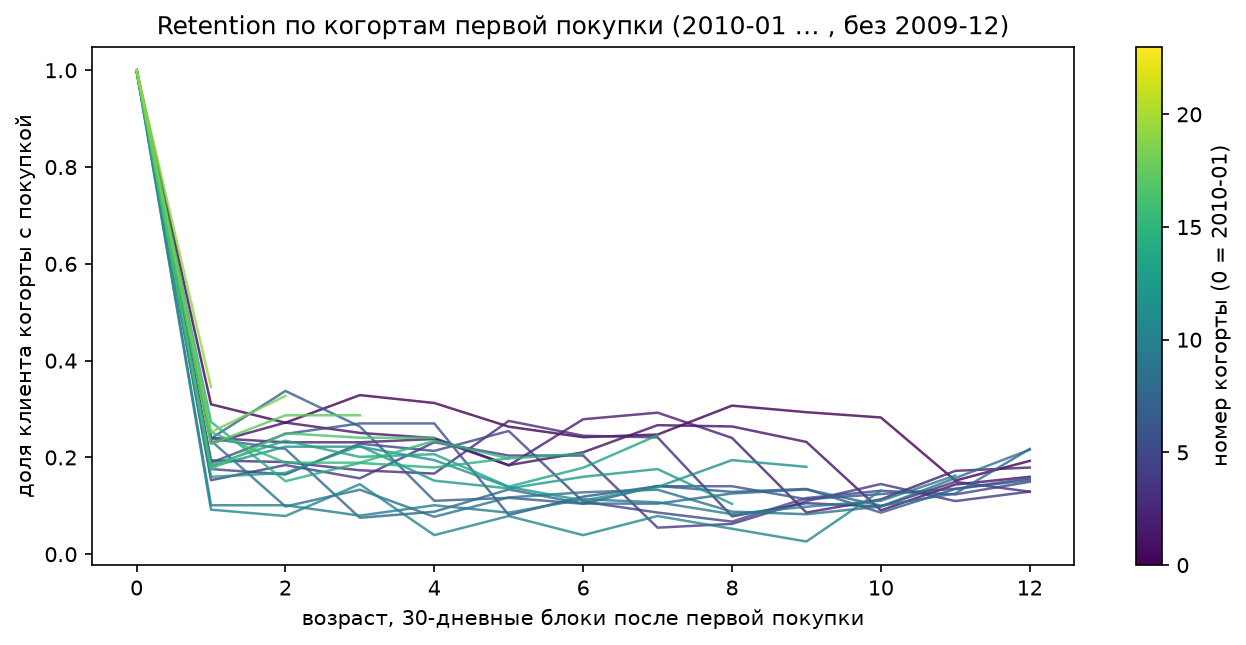

In [3]:
import matplotlib as mpl
use = ret.iloc[1:]
fig, ax = plt.subplots(figsize=(9, 4.4), dpi=150)
cmap = plt.get_cmap('viridis')
for i, (c, row) in enumerate(use.iterrows()):
    ax.plot(row.index, row.values, color=cmap(i / len(use)), lw=1.2, alpha=.8)
ax.set(xlabel='возраст, 30-дневные блоки после первой покупки', ylabel='доля клиента когорты с покупкой',
       title='Retention по когортам первой покупки (2010-01 … , без 2009-12)')
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=mpl.colors.Normalize(0, len(use)-1))
fig.colorbar(sm, ax=ax, label='номер когорты (0 = 2010-01)')
fig.tight_layout(); fig.savefig(FIG / '05-cohort-retention.png'); plt.show()

Каждая линия — когорта; обрыв линии — граница наблюдаемости. После падения до 21,6 % на возрасте 1 доля активных убывает медленно (см. взвешенную таблицу ниже: 17,6 % на возрасте 6, 12,9 % на 10) и не геометрически. Это доля активных в блоке, а не выживание: клиент может пропустить блок и вернуться. Возврат кривых вверх на возрасте 11–12 — гипотеза: сезонность (поздняя осень); не проверялось, и на этих возрастах наблюдаются только ранние когорты.

In [4]:
pooled = []
for k in range(13):
    ok = use[k].notna()
    n = size.iloc[1:][ok]
    pooled.append((use[k][ok] * n).sum() / n.sum() if ok.any() else np.nan)
pooled = pd.Series(pooled, name='retention, взвешенно по размеру когорт')
pooled.round(3).to_frame().T

,0,1,2,3,4,5,6,7,8,9,10,11,12
"retention, взвешенно по размеру когорт",1.0,0.216,0.208,0.202,0.189,0.174,0.176,0.179,0.152,0.139,0.129,0.146,0.172


## Revenue на клиента по возрасту (накопленная кривая)

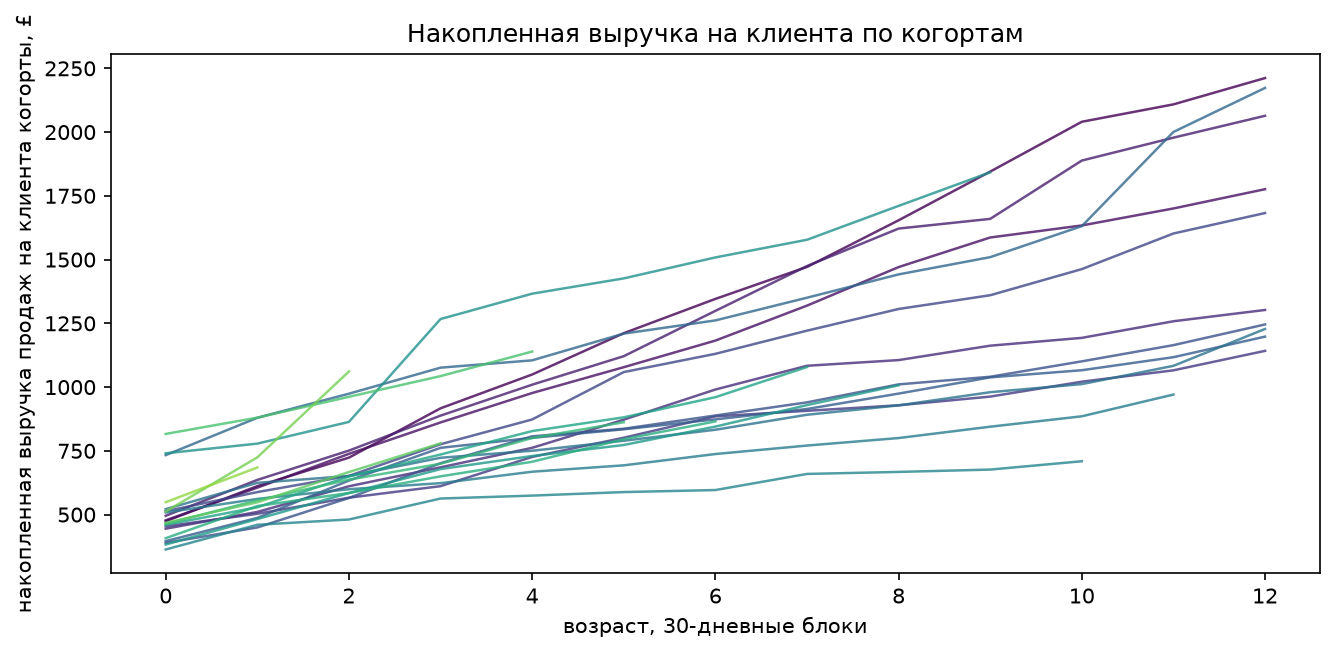

медиана когорт на последней наблюдаемой точке, £: 971


In [5]:
cum = rpc.iloc[1:].cumsum(axis=1, skipna=False)
fig, ax = plt.subplots(figsize=(9, 4.4), dpi=150)
for i, (c, row) in enumerate(cum.iterrows()):
    ax.plot(row.index, row.values, color=cmap(i / len(cum)), lw=1.2, alpha=.8)
ax.set(xlabel='возраст, 30-дневные блоки', ylabel='накопленная выручка продаж на клиента когорты, £',
       title='Накопленная выручка на клиента по когортам')
fig.tight_layout(); fig.savefig(FIG / '06-cohort-cumulative-revenue.png'); plt.show()
last = cum.apply(lambda r: r.dropna().iloc[-1]); print('медиана когорт на последней наблюдаемой точке, £:', round(last.median()))

Кривая используется как основа для бейзлайна B4 (сумма когортной кривой) и для выбора точки `t` бейзлайна B3 (шаг 6). Разброс между когортами по накопленной выручке — прямая оценка того, насколько среднее по когорте (B1) «не знает» о конкретной когорте.

## Возраст от даты против календарного месяца

Сравнение на одних и тех же когортах: доля вернувшихся в возрасте 1 (30–59 дней после первой покупки) против доли купивших в следующем календарном месяце.

In [6]:
cal = calendar_retention(tx, feats)
cmp_ = pd.DataFrame({'age_aligned': ret[1], 'calendar_next_month': cal[1]}).dropna()
cmp_['diff'] = cmp_.calendar_next_month - cmp_.age_aligned
print(cmp_.iloc[1:].round(3).describe().loc[['count','mean','std','min','max']])
first = feats.first_purchase
dom = first.dt.day
print('доля клиентов, чья первая покупка приходится на последнюю неделю месяца (дни 24+):', f'{(dom >= 24).mean():.1%}')

       age_aligned  calendar_next_month       diff
count    21.000000            21.000000  21.000000
mean      0.211857             0.201381  -0.010429
std       0.061629             0.044040   0.037890
min       0.092000             0.092000  -0.095000
max       0.346000             0.271000   0.074000
доля клиентов, чья первая покупка приходится на последнюю неделю месяца (дни 24+): 20.3%


Смысл ошибки календарной когорты: клиент, купивший 28-го, получает в «следующем месяце» окно в 31 день после первой покупки, а купивший 2-го — до 60. Окна в среднем сравнимы, но разные для разных клиентов, и при экстраполяции `p^N` эта вариация возводится в степень. На возрасте 1 (21 когорта, парное сравнение) календарный вариант ниже на 1,0 п.п., стандартное отклонение разностей 3,8 п.п., то есть разница неотличима от шума. На возрастах 4–8 календарные доли выше на 0,8–1,7 п.п. (средние по когортам, не парные: наборы наблюдаемых когорт различаются; интервалов нет). Вывод осторожный: эффект в этих данных мал, в README заявляется метод (возраст от даты), а не выигрыш от него.

In [7]:
pd.DataFrame({'age_aligned': ret.iloc[1:, :9].mean().round(3), 'calendar': cal.iloc[1:, :9].mean().round(3)}).T

,0,1,2,3,4,5,6,7,8
age_aligned,1.0,0.212,0.211,0.205,0.183,0.164,0.160,0.164,0.138
calendar,1.0,0.207,0.217,0.210,0.199,0.181,0.173,0.172,0.148
